In [1]:
#!source /n/holylfs05/LABS/arguelles_delgado_lab/Everyone/jbook/i3/build/env-shell.sh

In [2]:
from I3Tray import I3Tray
from icecube import icetray, dataio, dataclasses, simclasses
from icecube.LeptonInjector import weight_hnl_generation, load_generation_weighting_files, weight_hnl_lifetime_framewise
from icecube.LeptonInjector.oscnext_frame_objects_weighting import create_weight_dict
from icecube.LeptonInjector import hnl_weighting
from icecube.LeptonInjector.oscnext_tools_misc import UpdateFrameObject
import LeptonWeighter as LW

from icecube import icetray, dataio, dataclasses, LeptonInjector
from icecube import tableio, hdfwriter
from I3Tray import I3Units

from icecube.LeptonInjector import hdf5_to_feather
from collections import OrderedDict

try: from tqdm import tqdm
except: tqdm = lambda x: x
    
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os
import glob as glob

/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/site-packages/ipykernel_launcher.py:1: UserWarning: Using `import I3Tray` or `from I3Tray import *` is now considered depricated. Please switch to using `from icecube.icetray import I3Tray`
  """Entry point for launching an IPython kernel.
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/importlib/_bootstrap.py:219: RuntimeWarning: to-Python converter for std::vector<char, std::allocator<char> > already registered; second conversion method ignored.
  return f(*args, **kwds)
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/importlib/_bootstrap.py:219: RuntimeWarning: to-Python converter for std::vector<std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >, std::allocator<std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > > > already registered; second conversion method ignored.
  return f(*args, **kwds)
/cvmfs/

In [32]:
import seaborn as sns

In [3]:
event_dir = "/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/reconstructed"
signal_dir = f"{event_dir}/test_190300/"
background_dir = f"{event_dir}/oscNext/"

In [69]:
loc_keys = [
    # true HNL variables
    "HNL_true_x",
    "HNL_true_y",
    "HNL_true_z",
    "HNL_true_energy",
    "HNL_true_zenith",
    "HNL_true_azimuth",
    "HNL_true_time",
    # true primary variables
    "true_x",
    "true_y",
    "true_z",
    "true_energy",
    "true_zenith",
    "true_azimuth",
    "true_time",
    # true first (DIS) cascade variables
    "casc0_true_x",
    "casc0_true_y",
    "casc0_true_z",
    "casc0_true_energy",
    "casc0_true_zenith",
    "casc0_true_azimuth",
    "casc0_true_time",
    # true second (HNL decay) cascade variables
    "casc1_true_x",
    "casc1_true_y",
    "casc1_true_z",
    "casc1_true_energy",
    "casc1_true_zenith",
    "casc1_true_azimuth",
    "casc1_true_time",
]

# function to get HNL true variables
def get_pid_score(files, nfiles=None):
    info = {"type":[], "pid score": [], "primary energy": [], "weight": []}
    pid_key = "dynedge_hnl_pid_test_pid"
   
    if nfiles is None: nfiles = len(files)

    # Loop over the files
    for f in tqdm(files):
        i3file = dataio.I3File(f)
        
        # And loop through frames for this file
        while i3file.more():
            frame = i3file.pop_frame()
            
            if frame.Stop != icetray.I3Frame.DAQ: 
                continue
            mctree = frame["I3MCTree"]
            p_true = mctree.primaries[0]
            pid = str(p_true.type)
            energy= p_true.energy
            try:
                weight = frame["I3MCWeightDict"]["TotalInteractionProbabilityWeight"]
            except:
                weight = frame["I3MCWeightDict"]["ReferenceWeight_1e-03"]
            
            frame = i3file.pop_frame()
            if frame.Stop != icetray.I3Frame.Physics: 
                continue
            pid_score = frame[pid_key]
            info["type"].append(pid)
            info["pid score"].append(pid_score.value)
            info["primary energy"].append(energy)
            info["weight"].append(weight)
    
    return info

In [70]:
signal_files = glob.glob(f"{signal_dir}/*")
neutrino_files = glob.glob(f"{background_dir}/*")

In [71]:
nu_info = get_pid_score(neutrino_files)

100%|██████████| 15/15 [00:46<00:00,  3.09s/it]


In [73]:
nu_info = pd.DataFrame(nu_info)

In [75]:
hnl_info = get_pid_score(signal_files)

100%|██████████| 1/1 [00:52<00:00, 52.84s/it]


In [76]:
hnl_info=pd.DataFrame(hnl_info)

In [103]:
mask = hnl_info["weight"]>0
hnl_info=hnl_info[mask]

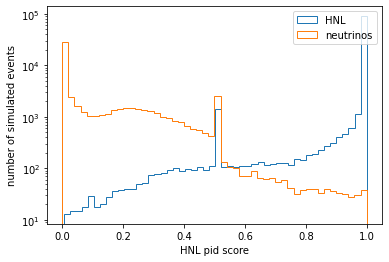

In [104]:
binning = 50

plt.hist(hnl_info["pid score"], histtype="step", label = "HNL", bins = binning)
plt.hist(nu_info["pid score"], histtype="step", label = "neutrinos", bins = binning)
plt.yscale("log")
plt.xlabel("HNL pid score")
plt.ylabel("number of simulated events")
plt.legend()

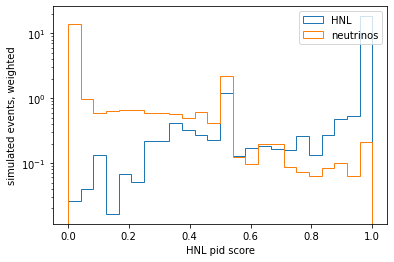

In [107]:
binning = np.linspace(0, 1, 25)

plt.hist(hnl_info["pid score"], histtype="step", label = "HNL", weights = hnl_info["weight"], bins = binning, density=True)
plt.hist(nu_info["pid score"], histtype="step", label = "neutrinos", weights = nu_info["weight"],bins = binning, density=True)
plt.yscale("log")
plt.xlabel("HNL pid score")
plt.ylabel("simulated events, weighted")
# plt.ylim([10e-40, 10e-3])
plt.legend()

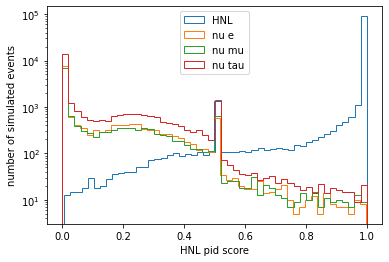

In [142]:
binning = 50
e_mask = (nu_info["type"]=="NuE") | (nu_info["type"]=="NuEBar")
mu_mask = (nu_info["type"]=="NuMu") | (nu_info["type"]=="NuMuBar")
tau_mask = (nu_info["type"]=="NuTau") | (nu_info["type"]=="NuTauBar")

plt.hist(hnl_info["pid score"], histtype="step", label = "HNL", bins = binning)
plt.hist(nu_info["pid score"][e_mask], histtype="step", label = "nu e", bins = binning)
plt.hist(nu_info["pid score"][mu_mask], histtype="step", label = "nu mu", bins = binning)
plt.hist(nu_info["pid score"][tau_mask], histtype="step", label = "nu tau", bins = binning)
plt.yscale("log")
plt.xlabel("HNL pid score")
plt.ylabel("number of simulated events")
plt.legend(loc="upper center")

Text(0, 0.5, 'Proportion of events')

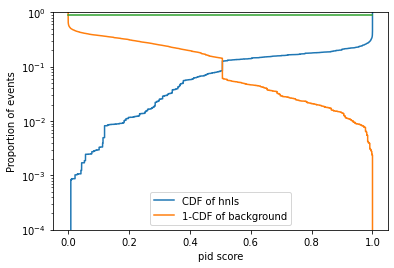

In [149]:
#Make CDF of the above plot. What's the fraction of neutrino background above a given pid score?#
#What's the fraction of hnls below a given pid score?
#MAke weighted version of the above - we need to know the impact of the flux to do science!!!!


ax1 = sns.ecdfplot(
    data=hnl_info, 
    x='pid score', 
    stat='proportion', 
    complementary=False, 
    log_scale=[False, True],
    weights='weight',
    label="CDF of hnls")
ax = sns.ecdfplot(
    data=nu_info, 
    x='pid score', 
    stat='proportion', 
    complementary=True, 
    log_scale=[False, True],
    weights='weight',
    label="1-CDF of background")

ax.plot(np.linspace(0, 1, 10), np.ones(10)*0.9)
ax.set_ylim([10**(-4), 1])
ax.legend()
ax.set_ylabel("Proportion of events")

In [125]:
def get_purity_and_efficiency(threshold = 0.38):
    background_pid_mask = nu_info["pid score"]>threshold
    hnl_pid_mask = hnl_info['pid score']>threshold

    background_like_hnl = np.sum(nu_info[background_pid_mask]['weight'])
    hnl_like_hnl = np.sum(hnl_info[hnl_pid_mask]['weight'])
    all_hnl = np.sum(hnl_info['weight'])
    
#     print("Threshold: " + str(threshold))
#     print("Purity: " + str(hnl_like_hnl/(hnl_like_hnl + background_like_hnl)))
#     print("Efficiency: " + str(hnl_like_hnl/all_hnl))
    
    purity = hnl_like_hnl/(hnl_like_hnl + background_like_hnl)
    efficiency = hnl_like_hnl/all_hnl
    
    return purity, efficiency

In [151]:
threshold = 0.5
background_pid_mask = nu_info["pid score"]>threshold
hnl_pid_mask = hnl_info['pid score']>threshold

background_like_hnl = np.sum(nu_info[background_pid_mask]['weight'])
hnl_like_hnl = np.sum(hnl_info[hnl_pid_mask]['weight'])
all_hnl = np.sum(hnl_info['weight'])

In [154]:
print(hnl_like_hnl/all_hnl)

0.9163856205860761


In [155]:
cutoffs = np.linspace(0, 1, 100)

purity = []
efficiency = []

for cutoff in cutoffs:
    p, e = get_purity_and_efficiency(cutoff)
    purity.append(p)
    efficiency.append(e)

/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/site-packages/ipykernel_launcher.py:13: RuntimeWarning: invalid value encountered in double_scalars
  del sys.path[0]


In [166]:
scaled_purity = [item * 100 for item in purity]

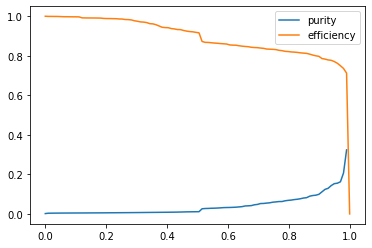

In [168]:
plt.plot(cutoffs, scaled_purity, label="purity x100")
plt.plot(cutoffs, efficiency, label="efficiency")
plt.legend()

In [174]:
def get_purity_and_efficiency_uw(threshold = 0.38):
    background_pid_mask = nu_info["pid score"]>threshold
    hnl_pid_mask = hnl_info['pid score']>threshold

    background_like_hnl = len(nu_info[background_pid_mask])
    hnl_like_hnl = len(hnl_info[hnl_pid_mask])
    all_hnl = len(hnl_info)
    if (hnl_like_hnl + background_like_hnl) ==0:
        purity = 1
    else:
        purity = hnl_like_hnl/(hnl_like_hnl + background_like_hnl)
    efficiency = hnl_like_hnl/all_hnl
    
    return purity, efficiency

In [175]:
cutoffs = np.linspace(0, 1, 100)

uw_purity = []
uw_efficiency = []

for cutoff in cutoffs:
    p, e = get_purity_and_efficiency_uw(cutoff)
    uw_purity.append(p)
    uw_efficiency.append(e)

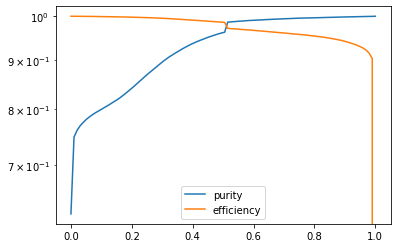

In [177]:
plt.plot(cutoffs, uw_purity, label="purity")
plt.plot(cutoffs, uw_efficiency, label="efficiency")
plt.legend()
plt.yscale('log')